## Jack Chou

### Load Data

In [16]:
# Loads the temperature data for Math 50 Assignment 3 into dataframes `mbh`
# and `hadcrut`.
# Data is loaded directly from math50-data (raw GitHub URLs), so this
# notebook runs as-is in Colab.

# Load Script Source: Ethan Levien
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [17]:
MBH_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/mbh99-nh-temperature.csv"
HADCRUT_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/hadcrut5-nh-annual.csv"


def load_mbh():
    # columns: year, recon (reconstructed temperature, 1000-1980),
    # inst (the thermometer record MBH used, 1902-1998) and
    # se (reported standard error of recon, 1000-1901).
    # Missing values are NaN.
    return pd.read_csv(MBH_URL)


def load_hadcrut(mbh):
    # columns: year, temp (HadCRUT5 Northern Hemisphere annual temperature,
    # 1850-present), shifted so that its 1902-1980 average matches mbh.inst
    # (the two records use different reference periods).
    out = pd.read_csv(HADCRUT_URL)[["year", "temp"]]
    both = out.merge(mbh, on="year")
    both = both[(both.year >= 1902) & (both.year <= 1980)]
    out["temp"] = out["temp"] - (both["temp"] - both["inst"]).mean()
    return out


mbh = load_mbh()
hadcrut = load_hadcrut(mbh)
mbh.head()

,year,recon,inst,se
0,1000,0.0659,NaN,0.240346
1,1001,-0.1241,NaN,0.240347
2,1002,-0.1208,NaN,0.240346
3,1003,-0.1801,NaN,0.240347
4,1004,-0.0711,NaN,0.240347


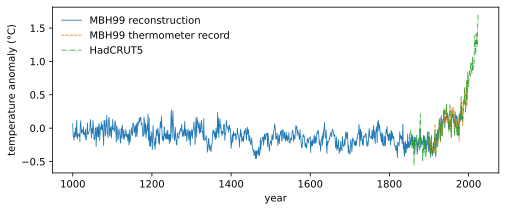

In [18]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mbh.year, mbh.recon, lw=0.8, label="MBH99 reconstruction")
ax.plot(mbh.year, mbh.inst, "--", lw=0.8, label="MBH99 thermometer record")
ax.plot(hadcrut.year, hadcrut.temp, "-.", lw=0.8, label="HadCRUT5")
ax.set_xlabel("year")
ax.set_ylabel("temperature anomaly (°C)")
ax.legend(frameon=False)
plt.show()

## Part 1: Reading MBH

### 1.1 The shaded region in Figure 3

In the simplified model, the band is

$$\hat T_i \pm 2\hat\sigma_\epsilon, \qquad \hat\sigma_\epsilon^2 = \frac{1}{N - N_c - 1}\sum_{i=N_c}^{N} r_i^2, \qquad r_i = T_i - (\hat\beta_0 + \hat\beta_1 P_i),$$

where $\hat\sigma_\epsilon$ is the residual standard deviation from fitting model (1) on the 79 calibration years (1902 to 1980). Since the model has a single $\sigma_\epsilon$, the band has the same width in every year.

It is not clear from the paper what the regions represent. The caption only says "two standard error limits (shaded)", and the text only says that unresolved variance "in the secular (longer than the 79 year calibration interval in this case) and higher-frequency bands" is treated separately, without a formula (Mann et al., 1999, p. 761).

- The width is not constant. The se column steps up going back in time as the proxy network changes, so it is not $2\hat\sigma_\epsilon$ from one fit.
- The paper does not say whether the band is meant to contain $T_i$ or only describes $\hat T_i$, or whether coefficient uncertainty is included.
- The band is pointwise, so it says nothing about how errors in different years are related, even though the paper later quotes "decadal" and "centennial" standard errors.

The cell below compares $\hat\sigma_\epsilon$ from the residuals inst - recon with the reported se.

In [19]:
cal = mbh[(mbh.year >= 1902) & (mbh.year <= 1980)]
r = cal.inst.to_numpy() - cal.recon.to_numpy() # calibration residuals
sigma_hat = np.sqrt(np.sum(r**2) / (len(r) - 2))
print("simplified-model sigma_hat from 1902-1980 residuals:", sigma_hat.round(3))
print("half-width of the simplified band (2 sigma_hat):  ", (2 * sigma_hat).round(3))

# the reported se is constant within each period of the proxy network; print where it changes
se_obs = mbh.dropna(subset=["se"])
se_vals = se_obs.se.round(3).to_numpy()
se_yrs = se_obs.year.to_numpy()
starts = [0] + [i for i in range(1, len(se_vals)) if se_vals[i] != se_vals[i - 1]]
for k, i in enumerate(starts):
    end = se_yrs[starts[k + 1] - 1] if k + 1 < len(starts) else se_yrs[-1]
    print(f"{se_yrs[i]}-{end}: se = {se_vals[i]}")

simplified-model sigma_hat from 1902-1980 residuals: 0.098
half-width of the simplified band (2 sigma_hat):   0.195
1000-1399: se = 0.24
1400-1449: se = 0.244
1450-1499: se = 0.246
1500-1599: se = 0.244
1600-1649: se = 0.133
1650-1699: se = 0.122
1700-1749: se = 0.124
1750-1759: se = 0.129
1760-1779: se = 0.122
1780-1819: se = 0.116
1820-1901: se = 0.113


The simplified band is about $\pm 0.2$°C in every year. The reported se is close to $\hat\sigma_\epsilon$ after 1820 (0.11) but more than twice as large before 1600 (0.24), so MBH did more than the simplified calculation.

### 1.2 The two claims as probability statements

Let $T_{1000}, \dots, T_{1998}$ be the true temperatures and $c$ the "moderately high" confidence level (the conclusion says "likely", so roughly 2/3 or more).

1. Warmest decade.
$$P\left(\frac{1}{10}\sum_{i=1989}^{1998} T_i \;>\; \frac{1}{10}\sum_{i=j}^{j+9} T_i \ \text{ for every other window } j = 1000, \dots, 1979\right) \ge c.$$
2. Warmest year.
$$P\left(T_{1998} > T_i \text{ for all } i = 1000, \dots, 1997\right) = P\left(T_{1998} > \max_{i < 1998} T_i\right) \ge c.$$

The years 1902 to 1998 are thermometer data and treated as known, so the randomness is only in the earlier years, where $T_i = \hat T_i - e_i$ and $s_i$ is the reported standard error of $\hat T_i$ (the se column). Both claims are about all earlier years at once.


### 1.3 Are the marginals $e_i \sim \text{Normal}(0, s_i^2)$ enough?

No. The marginals give $P(T_i < T_{1998}) = \Phi\big((T_{1998} - \hat T_i)/s_i\big)$ for each year alone, but "1998 beats every year" is an intersection of 902 events, so its probability depends on how the $e_i$ move together. The same holds for decade averages:

$$\text{var}\left(\frac{1}{10}\sum_{i=j}^{j+9} e_i\right) = \frac{1}{100}\sum_{i}\sum_{k}\text{cov}(e_i, e_k),$$

which is $\frac{1}{100}\sum_i s_i^2 \approx s^2/10$ for independent errors but $s^2$ for perfectly correlated ones.

To show this, I keep $e_i \sim \text{Normal}(0, s_i^2)$ and compare independent errors ($e_i = s_i Z_i$), AR(1) errors ($Z_i$ an AR(1) with $\rho = 0.9$), and perfectly correlated errors ($e_i = s_i Z$). For the year claim, the two extremes have closed forms: $\prod_i \Phi\big((T_{1998} - \hat T_i)/s_i\big)$ (independent) and $1 - \Phi\big(\max_i (\hat T_i - T_{1998})/s_i\big)$ (perfectly correlated).

In [20]:
from scipy.stats import norm

pre = mbh[mbh.year <= 1901]
T_hat = pre.recon.to_numpy() # reconstruction, 1000-1901
s = pre.se.to_numpy() # reported standard error, 1000-1901
n_pre = len(T_hat)

inst = mbh.inst.to_numpy()
yrs = mbh.year.to_numpy()
T1998 = inst[yrs == 1998][0]
T_decade = np.mean(inst[(yrs >= 1989) & (yrs <= 1998)])
print("T_1998 =", T1998, "  mean of 1989-1998 =", T_decade.round(3))

# instrumental windows 1902-1988 are known; check they are all cooler than 1989-1998
inst_windows = [np.mean(inst[(yrs >= j) & (yrs <= j + 9)]) for j in range(1902, 1980)]
print("warmest instrumental window before 1989:", np.max(inst_windows).round(3))

p_indep = np.prod(norm.cdf((T1998 - T_hat) / s))
p_perfect = 1 - norm.cdf(np.max((T_hat - T1998) / s))
print("P(1998 warmest), independent errors (exact):", p_indep.round(3))
print("P(1998 warmest), perfectly correlated errors (exact):", p_perfect.round(3))

T_1998 = 0.78   mean of 1989-1998 = 0.481
warmest instrumental window before 1989: 0.249
P(1998 warmest), independent errors (exact): 0.708
P(1998 warmest), perfectly correlated errors (exact): 0.983


In [21]:
rng = np.random.default_rng(50)


def error_z(kind, n, rho=0.9):
    # standardized errors Z_1..Z_n, each Normal(0, 1), with three different joint distributions
    if kind == "independent":
        return rng.normal(0, 1, n)
    if kind == "perfect":
        return np.full(n, rng.normal(0, 1))
    z = np.empty(n) # stationary AR(1) with variance 1
    z[0] = rng.normal(0, 1)
    for i in range(1, n):
        z[i] = rng.normal(rho * z[i - 1], np.sqrt(1 - rho**2))
    return z


def max_decade(x):
    # largest 10-year moving average of x
    c = np.concatenate([[0], np.cumsum(x)])
    return np.max((c[10:] - c[:-10]) / 10)


n_rep = 4000
rows = {}
for kind in ["independent", "AR(1), rho = 0.9", "perfect"]:
    year_ok, decade_ok = 0, 0
    for rep in range(n_rep):
        T = T_hat - s * error_z(kind.split(",")[0], n_pre) # one plausible history, 1000-1901
        year_ok += T.max() < T1998
        decade_ok += max_decade(T) < T_decade
    rows[kind] = [year_ok / n_rep, decade_ok / n_rep]

pd.DataFrame(rows, index=["P(1998 warmest year)", "P(1989-1998 warmest decade)"]).round(3)

,independent,"AR(1), rho = 0.9",perfect
P(1998 warmest year),0.705,0.804,0.982
P(1989-1998 warmest decade),1.000,0.655,0.944


The yearly bands are identical in all three cases, but the probability that 1998 is the warmest year ranges from about 0.71 (independent) to 0.98 (perfectly correlated). For the decade the order flips: independent errors average out and give probability 1, while AR(1) errors drop it to about 0.66. Therefore, we need the joint distribution of $(e_{1000}, \dots, e_{1901})$, not just the marginals. (The data give 0.48 for the 1989 to 1998 mean; the paper quotes 0.45.)

### 1.4 The linearity assumption

"Data and Method" section (p. 759 to 760):

> "The calibration procedure (see MBH98) invokes the assumptions (1) that a linear relationship exists between proxy climate indicators and and some combination of large-scale temperature patterns, and (2) that patterns of surface temperature in the past can be suitably described in terms of some linear combination of the dominant present-day surface temperature patterns."


### 1.5 Remaking the hockey stick and the correlations $\rho_k$

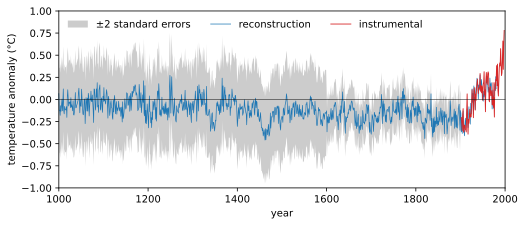

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(mbh.year, mbh.recon - 2 * mbh.se, mbh.recon + 2 * mbh.se, color="0.8", lw=0, label="±2 standard errors")
ax.plot(mbh.year, mbh.recon, lw=0.7, color="C0", label="reconstruction")
ax.plot(mbh.year, mbh.inst, lw=0.9, color="C3", label="instrumental")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlim(1000, 2000)
ax.set_ylim(-1, 1)
ax.set_xlabel("year")
ax.set_ylabel("temperature anomaly (°C)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()

The sample autocorrelation uses the formula $\hat\rho_k = \sum_t (Y_t - \bar Y)(Y_{t+k} - \bar Y) / \sum_t (Y_t - \bar Y)^2$. I also look at the year-to-year changes $Y_t - Y_{t-1}$.

reconstruction (1000-1980)       rho_1 = 0.65, rho_10 = 0.42
instrumental (1902-1998)         rho_1 = 0.75, rho_10 = 0.40
reconstruction, yearly changes   rho_1 = -0.36, rho_10 = 0.06


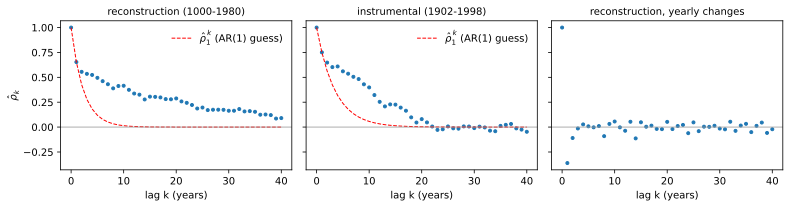

In [23]:
def acf(y, max_lag=40):
    # sample autocorrelation rho_k for k = 0..max_lag
    y = np.asarray(y, dtype=float)
    d = y - np.mean(y)
    return np.array([np.sum(d[:len(d) - k] * d[k:]) / np.sum(d**2) for k in range(max_lag + 1)])


recon = mbh.recon.dropna().to_numpy() # 1000-1980
inst_obs = mbh.inst.dropna().to_numpy() # 1902-1998
series = {
    "reconstruction (1000-1980)": recon,
    "instrumental (1902-1998)": inst_obs,
    "reconstruction, yearly changes": np.diff(recon),
}

lags = np.arange(41)
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for j, (name, y) in enumerate(series.items()):
    rho_hat = acf(y)
    ax[j].plot(lags, rho_hat, "o", markersize=3)
    if j < 2:
        ax[j].plot(lags, rho_hat[1] ** lags, "r--", lw=1, label=r"$\hat\rho_1^{\,k}$ (AR(1) guess)")
        ax[j].legend(frameon=False)
    ax[j].axhline(0, color="0.6", lw=0.8)
    ax[j].set_title(name, fontsize=10)
    ax[j].set_xlabel("lag k (years)")
    print(f"{name:32s} rho_1 = {rho_hat[1]:.2f}, rho_10 = {rho_hat[10]:.2f}")
ax[0].set_ylabel(r"$\hat\rho_k$")
plt.tight_layout()
plt.show()

- The reconstruction's correlation decays more slowly than an AR(1) with the same $\hat\rho_1$ (red), which points to slow, century-scale variation such as the cooling trend MBH describe. The instrumental series stays correlated for about 20 years because of the 20th century trend.
- The yearly changes are close to uncorrelated after lag 1 (apart from a negative $\hat\rho_1$): differencing removes the slow part.

Hence, errors in this kind of reconstruction are likely correlated over many years too, which is when the yearly band misleads most (see 1.3).

## Part 2: Simulating a toy model

### 2.1 Conditional independence of the proxies

It says a tree's ring width in year $i$ depends only on that year's temperature plus fresh noise, so the tree has no memory. I do not think this is reasonable since:

- In a good year a tree stores sugars and grows more roots and leaves, so growth carries over into the next year even at a fixed temperature.
- Drought, tree age and CO₂ act over many years. MBH99 itself reports "long-term growth increases that are more dramatic than can be explained by instrumental temperature trends" in ITRDB PC #1, and too much residual variance at long periods ("a roughly five-fold increase in unresolved variance is observed at secular frequencies"). ITRDB PC #1 is a single summary series (the first principal component) of the 28 North American tree-ring records in the International Tree Ring Data Bank that go back to AD 1000 (MBH99, p. 759).

### 2.2 Marginal distribution of $P_i$

Write $P_i = a + bT_i + \eta_i$ with $\eta_i \sim \text{Normal}(0, \sigma_P^2)$ independent of $T_i \sim \text{Normal}(0, \sigma_T^2)$. A linear combination of independent Normals is Normal, so for every year

$$P_i \sim \text{Normal}\left(a,\; b^2\sigma_T^2 + \sigma_P^2\right) = \text{Normal}(0,\; 0.04 + 0.0625) = \text{Normal}(0,\; 0.1025).$$

Since $(T_i, P_i)$ is jointly Normal, the regression of $T_i$ on $P_i$ is exactly linear, with

$$\beta_1 = \frac{b\sigma_T^2}{b^2\sigma_T^2 + \sigma_P^2} = \frac{0.04}{0.1025} \approx 0.390, \qquad \beta_0 = E[T] - \beta_1 E[P] = -\beta_1 a = 0,$$

$$\sigma_\epsilon^2 = \text{var}(T) - \beta_1^2\text{var}(P) = \frac{\sigma_T^2\sigma_P^2}{b^2\sigma_T^2 + \sigma_P^2} \approx 0.0244, \qquad \sigma_\epsilon \approx 0.156.$$

Because $\beta_1 < 1/b = 1$, the reconstruction has variance $\beta_1^2\,\text{var}(P) = 0.0156$ versus $\text{var}(T_i) = 0.04$, so it is flatter than the true temperature (regression to the mean).

In [24]:
# parameters of the null model
phi, sigma_T, a, b, sigma_P = 0.9, 0.2, 0.0, 1.0, 0.25
years = np.arange(1000, 1981) # i = 1..N  <->  1000..1980
N = len(years) # 981
Nc = int(np.where(years == 1902)[0][0]) # position of 1902 (902 when counting from 0)

beta1_true = b * sigma_T**2 / (b**2 * sigma_T**2 + sigma_P**2)
beta0_true = a - beta1_true * a - a # = -beta1 * a (written this way to avoid printing -0.000)
sigma_eps_true = np.sqrt(sigma_T**2 * sigma_P**2 / (b**2 * sigma_T**2 + sigma_P**2))
print("N =", N, " Nc (0-based index of 1902) =", Nc)
print("var(P) =", b**2 * sigma_T**2 + sigma_P**2)
print(f"beta1 = {beta1_true:.3f}, beta0 = {beta0_true:.3f}, sigma_eps = {sigma_eps_true:.3f}")

N = 981  Nc (0-based index of 1902) = 902
var(P) = 0.10250000000000001
beta1 = 0.390, beta0 = 0.000, sigma_eps = 0.156


### 2.3 Simulating $T_i$ and $P_i$

We start with $T_1 \sim \text{Normal}(0, \sigma_T^2)$. Then each year $T_i \sim \text{Normal}(\varphi T_{i-1}, \sigma_T^2(1-\varphi^2))$, and given the temperatures, each proxy is an independent draw $P_i \sim \text{Normal}(a + bT_i, \sigma_P^2)$.

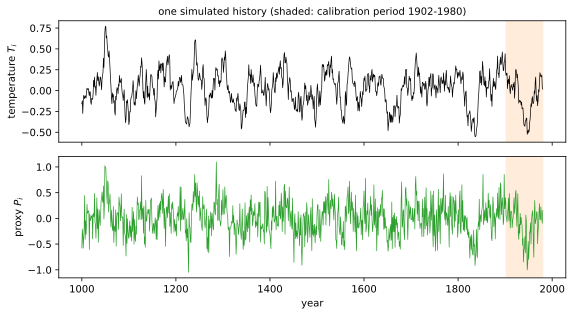

sample var(T) = 0.0446 (theory 0.04)
sample var(P) = 0.1065 (theory 0.1025)
sample lag-1 corr of T = 0.905 (theory 0.9)


In [25]:
def simulate(rng, N=N, phi=phi, sigma_T=sigma_T, a=a, b=b, sigma_P=sigma_P):
    # temperatures: stationary AR(1) started from its marginal distribution
    t = np.empty(N)
    t[0] = rng.normal(0, sigma_T)
    for i in range(1, N):
        t[i] = rng.normal(phi * t[i - 1], sigma_T * np.sqrt(1 - phi**2))
    # proxies: independent given the temperatures
    p = rng.normal(a + b * t, sigma_P)
    return t, p


rng = np.random.default_rng(2026)
t, p = simulate(rng)

fig, ax = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
ax[0].plot(years, t, lw=0.7, color="k")
ax[0].set_ylabel("temperature $T_i$")
ax[1].plot(years, p, lw=0.7, color="C2")
ax[1].set_ylabel("proxy $P_i$")
ax[1].set_xlabel("year")
for x in ax:
    x.axvspan(1902, 1980, color="C1", alpha=0.15)
ax[0].set_title("one simulated history (shaded: calibration period 1902-1980)", fontsize=10)
plt.tight_layout()
plt.show()

print("sample var(T) =", np.var(t, ddof=1).round(4), "(theory 0.04)")
print("sample var(P) =", np.var(p, ddof=1).round(4), "(theory 0.1025)")
print("sample lag-1 corr of T =", np.corrcoef(t[:-1], t[1:])[0, 1].round(3), "(theory 0.9)")

### 2.4 The reconstruction procedure

In [26]:
def reconstruct(t, p, rng, n_hist=3, Nc=Nc):
    # 1) fit model (1) on the calibration period only
    x, y = p[Nc:], t[Nc:]
    beta1_hat = np.sum((x - np.mean(x)) * (y - np.mean(y))) / np.sum((x - np.mean(x))**2)
    beta0_hat = np.mean(y) - beta1_hat * np.mean(x)
    resid = y - (beta0_hat + beta1_hat * x)
    sigma_hat = np.sqrt(np.sum(resid**2) / (len(y) - 2))

    # 2) reconstruction for every year and the 95% band
    T_hat = beta0_hat + beta1_hat * p
    lower, upper = T_hat - 2 * sigma_hat, T_hat + 2 * sigma_hat

    # 3) simulated histories: T_i ~ Normal(T_hat_i, sigma_hat^2) independently for i < Nc
    hist = [rng.normal(T_hat[:Nc], sigma_hat) for k in range(n_hist)]

    return {"beta0": beta0_hat, "beta1": beta1_hat, "sigma": sigma_hat,
            "T_hat": T_hat, "lower": lower, "upper": upper, "hist": hist}

rec = reconstruct(t, p, rng)
print(f"beta1_hat = {rec['beta1']:.3f} (theory {beta1_true:.3f})")
print(f"beta0_hat = {rec['beta0']:.3f} (theory {beta0_true:.3f})")
print(f"sigma_hat = {rec['sigma']:.3f} (theory {sigma_eps_true:.3f})")
inside = (t[:Nc] >= rec["lower"][:Nc]) & (t[:Nc] <= rec["upper"][:Nc])
print("share of pre-1902 years with the true T inside the band:", np.mean(inside).round(3))

beta1_hat = 0.464 (theory 0.390)
beta0_hat = -0.025 (theory 0.000)
sigma_hat = 0.142 (theory 0.156)
share of pre-1902 years with the true T inside the band: 0.907


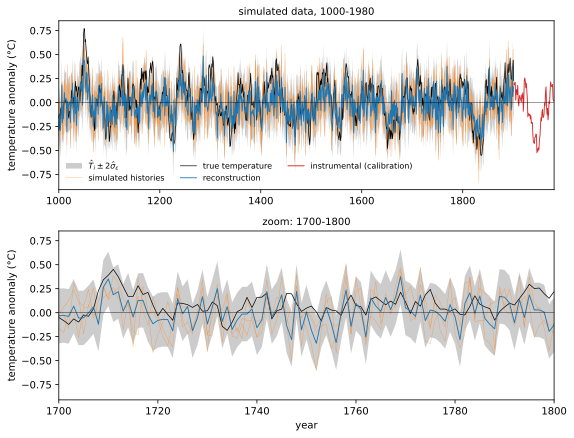

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6.2))
for ax, (lo, hi) in zip(axes, [(1000, 1981), (1700, 1800)]):
    ax.fill_between(years[:Nc], rec["lower"][:Nc], rec["upper"][:Nc], color="0.8", lw=0,
                    label=r"$\hat T_i \pm 2\hat\sigma_\epsilon$")
    for k, h in enumerate(rec["hist"]):
        ax.plot(years[:Nc], h, lw=0.4, color="C1", alpha=0.6, label="simulated histories" if k == 0 else None)
    ax.plot(years[:Nc], t[:Nc], lw=0.7, color="k", label="true temperature")
    ax.plot(years[:Nc], rec["T_hat"][:Nc], lw=0.9, color="C0", label="reconstruction")
    ax.plot(years[Nc:], t[Nc:], lw=0.9, color="C3", label="instrumental (calibration)")
    ax.axhline(0, color="k", lw=0.4)
    ax.set_xlim(lo, hi)
    ax.set_ylabel("temperature anomaly (°C)")
axes[0].set_title("simulated data, 1000-1980", fontsize=10)
axes[1].set_title("zoom: 1700-1800", fontsize=10)
axes[1].set_xlabel("year")
axes[0].legend(frameon=False, ncol=3, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

The plot looks like Figure 1. The reconstruction looks flat because $\hat\beta_1 < 1$ shrinks it toward the calibration mean, not because the climate was calm. The true temperature (black) stays above or below the reconstruction for decades, while the simulated histories only jitter around it from year to year.

### 2.5 Why the band understates the uncertainty

1. It ignores the uncertainty in $\hat\beta_0$, $\hat\beta_1$ and $\hat\sigma_\epsilon$. They come from only 79 years, and the error in $\hat\beta_1$ is shared by every year of the reconstruction. The calibration years are also an AR(1) with $\varphi = 0.9$, so they carry less information than 79 independent points, and $\hat\beta_1$ is biased low (Hurwicz bias).
2. It treats the errors as independent across years. With $a = 0$, $\epsilon_i = (\beta_1 b - 1)T_i + \beta_1\eta_i$, so for $k \ge 1$
$$\text{cov}(\epsilon_i, \epsilon_{i+k}) = (1 - \beta_1 b)^2\,\sigma_T^2\,\varphi^k, \qquad \text{corr}(\epsilon_i, \epsilon_{i+1}) = \frac{(1-\beta_1 b)^2\sigma_T^2\varphi}{\sigma_\epsilon^2} \approx 0.55.$$
Whole decades are off together, so independent draws make decade averages far too certain.

**Remedies.** For (1), draw new coefficients for each simulated history (or refit on many simulated calibration datasets), so the band includes the uncertainty in the fitted line. For (2), simulate whole histories with correlated errors (for example AR(1) residuals) and answer questions like "warmest decade" by counting across those histories.

The check below repeats the experiment in 300 simulated worlds.

In [28]:
rng = np.random.default_rng(7)
n_world, n_hist = 300, 200
coverage, beta1s, sigmas, err_lag1, decade_in, max_in = [], [], [], [], [], []

for w in range(n_world):
    t_w, p_w = simulate(rng)
    rec_w = reconstruct(t_w, p_w, rng, n_hist=n_hist)
    e = rec_w["T_hat"][:Nc] - t_w[:Nc] # true reconstruction errors
    coverage.append(np.mean(np.abs(e) <= 2 * rec_w["sigma"]))
    beta1s.append(rec_w["beta1"])
    sigmas.append(rec_w["sigma"])
    err_lag1.append(np.corrcoef(e[:-1], e[1:])[0, 1])

    # is the true warmest decade / warmest year inside the middle 95% of the simulated histories?
    hist_dec = np.array([max_decade(h) for h in rec_w["hist"]])
    hist_max = np.array([np.max(h) for h in rec_w["hist"]])
    decade_in.append(np.quantile(hist_dec, 0.025) <= max_decade(t_w[:Nc]) <= np.quantile(hist_dec, 0.975))
    max_in.append(np.quantile(hist_max, 0.025) <= np.max(t_w[:Nc]) <= np.quantile(hist_max, 0.975))

se_textbook = np.mean(sigmas) / (np.sqrt(len(years) - Nc) * np.sqrt(b**2 * sigma_T**2 + sigma_P**2))
print(f"pointwise coverage of the band: mean {np.mean(coverage):.3f}, "
      f"range {np.min(coverage):.2f} to {np.max(coverage):.2f} across worlds")
print(f"beta1_hat across worlds: mean {np.mean(beta1s):.3f} (true {beta1_true:.3f}), "
      f"sd {np.std(beta1s):.3f} vs textbook se {se_textbook:.3f}")
print(f"sigma_hat across worlds: mean {np.mean(sigmas):.3f} (true {sigma_eps_true:.3f})")
print(f"lag-1 corr of the true errors: {np.mean(err_lag1):.2f}  (independent draws: 0)")
print(f"true warmest pre-1902 decade inside the 95% range of the histories: {np.mean(decade_in):.3f}")
print(f"true warmest pre-1902 year inside the 95% range of the histories: {np.mean(max_in):.3f}")

pointwise coverage of the band: mean 0.881, range 0.53 to 0.99 across worlds
beta1_hat across worlds: mean 0.320 (true 0.390), sd 0.102 vs textbook se 0.049
sigma_hat across worlds: mean 0.140 (true 0.156)
lag-1 corr of the true errors: 0.64  (independent draws: 0)
true warmest pre-1902 decade inside the 95% range of the histories: 0.070
true warmest pre-1902 year inside the 95% range of the histories: 0.530


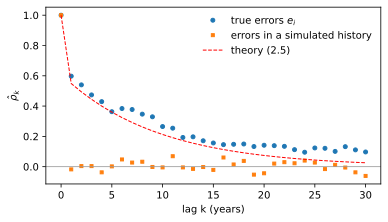

In [29]:
# autocorrelation of the true errors vs the errors in one set of independent draws (last world)
draw_err = rec_w["hist"][0] - rec_w["T_hat"][:Nc]
k = np.arange(31)
rho_theory = np.where(k == 0, 1.0, (1 - beta1_true * b)**2 * sigma_T**2 * phi**k / sigma_eps_true**2)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(k, acf(e, 30), "o", markersize=4, label="true errors $e_i$")
ax.plot(k, acf(draw_err, 30), "s", markersize=3, label="errors in a simulated history")
ax.plot(k, rho_theory, "r--", lw=1, label="theory (2.5)")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("lag k (years)")
ax.set_ylabel(r"$\hat\rho_k$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- The band covers the truth in about 88% of years instead of 95%, but this ranges from about 53% to 99% across worlds because the error in $\hat\beta_1$ is shared. The spread of $\hat\beta_1$ is about twice the textbook standard error.
- The true errors have lag-1 correlation of about 0.6; the simulated histories have none.
- The histories contain the true warmest decade in only about 7% of worlds, and the warmest year about half the time.

## Part 3: Extension and reflection

### 3.1 Adding CO₂

Expanded model. With $C_i$ the CO₂ concentration and $U_i$ the AR(1) from Part 2,

$$T_i = \gamma C_i + U_i, \qquad U_i \mid U_{i-1} \sim \text{Normal}\left(\varphi U_{i-1}, \sigma_T^2(1-\varphi^2)\right),$$

$$P_i \mid T_i, C_i \sim \text{Normal}\left(a + bT_i + cC_i,\; \sigma_P^2\right), \qquad Q_i \mid C_i \sim \text{Normal}\left(d + eC_i,\; \sigma_Q^2\right),$$

where $c$ is the direct CO₂ effect on tree growth and $Q_i$ is a CO₂ proxy (air bubbles in ice cores), used in place of $C_i$ before 1902. Model (1) becomes

$$T_i \mid P_i, Q_i \sim \text{Normal}\left(\beta_0 + \beta_1 P_i + \beta_2 Q_i,\; \sigma_\epsilon^2\right),$$

with $\beta_2 < 0$ when $c > 0$: for a fixed ring width, more CO₂ means it was colder.

Leaving CO₂ out. By the omitted-variable bias formula,

$$\beta_1' = \beta_1 + \beta_2\,\beta_{1,2}, \qquad \beta_{1,2} = \frac{\text{cov}(P, Q)}{\text{var}(P)}.$$

1. Level: pre-industrial CO₂ was lower than in any calibration year, so the model reads the narrower rings as cold. The past looks too cold by about $\beta_1' c\,(C_{\text{past}} - \bar C_{\text{calib}}) < 0$.
2. Slope: CO₂ and temperature rose together in 1902 to 1980, so $\beta_1' < \beta_1$ and past temperature swings are understated.

Both make the shaft (the flat, pre-1900 part of the curve) colder and flatter, which exaggerates the blade (the 20th-century rise). MBH99 "corrected" ITRDB PC #1 for this, and the NRC concluded that "strip-bark samples should be avoided for temperature reconstructions". Strip-bark trees are old trees, such as bristlecone pines, that have lost bark on part of the trunk, and the NRC report says their growth may respond to rising CO₂ rather than only to temperature.

The simulation below checks the level effect (CO₂ flat at 280 ppm before 1850 and 338 ppm in 1980, $\gamma = 0.5$°C, $c = 0.5$ per 100 ppm) by comparing proxies with and without the CO₂ growth effect.

In [30]:
C = np.full(N, 280.0)
late = years >= 1850
C[late] = 280 + 58 * ((years[late] - 1850) / 130)**2 # 280 ppm before 1850, 338 ppm in 1980
x_co2 = (C - 280) / 100 # CO2 in units of 100 ppm above pre-industrial
gamma, c_co2 = 0.5, 0.5
before = years < 1850

rng = np.random.default_rng(11)
bias_no, bias_co2, sd_ratio_no, sd_ratio_co2, b1_no, b1_co2 = [], [], [], [], [], []
for w in range(300):
    u, ignore = simulate(rng) # natural variability U_i
    t_w = u + gamma * x_co2 # temperature with CO2 warming
    noise = rng.normal(0, sigma_P, N)
    p_no = a + b * t_w + noise # proxy that responds to temperature only
    p_co2 = p_no + c_co2 * x_co2 # same proxy, plus CO2 growth effect
    r_no = reconstruct(t_w, p_no, rng, n_hist=0)
    r_co2 = reconstruct(t_w, p_co2, rng, n_hist=0)
    bias_no.append(np.mean(r_no["T_hat"][before] - t_w[before]))
    bias_co2.append(np.mean(r_co2["T_hat"][before] - t_w[before]))
    sd_ratio_no.append(np.std(r_no["T_hat"][before]) / np.std(t_w[before]))
    sd_ratio_co2.append(np.std(r_co2["T_hat"][before]) / np.std(t_w[before]))
    b1_no.append(r_no["beta1"])
    b1_co2.append(r_co2["beta1"])

pd.DataFrame({
    "proxy without CO2 effect": [np.mean(bias_no), np.mean(sd_ratio_no), np.mean(b1_no)],
    "proxy with CO2 effect": [np.mean(bias_co2), np.mean(sd_ratio_co2), np.mean(b1_co2)],
}, index=["mean error before 1850 (°C)", "sd(reconstruction) / sd(true), before 1850", "beta1_hat"]).round(3)

,proxy without CO2 effect,proxy with CO2 effect
mean error before 1850 (°C),0.098,0.047
"sd(reconstruction) / sd(true), before 1850",0.563,0.554
beta1_hat,0.347,0.341


With the CO₂ growth effect, the pre-1850 reconstruction is about 0.05°C colder, matching $\beta_1' c\,(0 - \bar x_{\text{calib}}) \approx 0.35 \times 0.5 \times (-0.3)$, where $x_i = (C_i - 280)/100$ is CO₂ in units of 100 ppm above pre-industrial, so $x_i = 0$ before 1850 and $\bar x_{\text{calib}} \approx 0.3$ over 1902 to 1980. The slope effect is small here because the 79-year CO₂ trend is small compared with year-to-year noise. Even without the CO₂ effect, the past comes out about 0.10°C too warm and about half as variable as the truth, because regression to the mean pulls it toward the warmer calibration mean.

### 3.2 Reflection

In this assignment, we looked at how much we can trust the shaded band in the MBH reconstruction. Before this assignment, I would have read the band as "the temperature was somewhere in here" and judged the 1990s claim by eye. However, a band can look fine year by year and still be wrong for the questions MBH actually cared about. Using the same yearly bands, the probability that 1998 was the warmest year ranged from about 0.71 to 0.98, and the only thing that changed was how the errors in different years were related to each other. This surprised me the most. The toy model made the problem even clearer. Across the simulated worlds, the band covered the truth in about 88% of years on average, yet the simulated histories contained the true warmest decade in only about 7% of worlds. Therefore, the band does poorly on exactly the two things MBH's headline claims are about, which are a decade average and a maximum over a thousand years. Also, the regression step flattens the past on its own, even before any CO₂ effect is added.

If I were presenting this to the public, I would show many plausible histories with correlated errors and coefficient uncertainty, and then state each claim as a probability across those histories. PAGES 2k (2019) took this approach and reported that "the warmest 10 yr (30 yr, 50 yr) period of the past two millennia falls within the second half of the twentieth century in 94% (89%, 84%) of ensemble members" (P.664). Their conclusion matches MBH's, but a number like that answers the decade question directly, which a shaded band cannot do. Beyond the numbers, reconstructions should also state what the band leaves out and which proxies drive the result. For example, MBH99 itself found that a single series, ITRDB PC #1, was "essential." No matter how clean a reconstruction looks, its uncertainty is only as honest as the assumptions behind it.

## LLM Statement

Model Used: Sonnet 5.5 in Claude Chat.

For this assignment, I used AI to build a conceptual understanding of the MBH reconstruction. I asked it why the marginals $e_i \sim \text{Normal}(0, s_i^2)$ are not enough to support a claim like "1998 is the warmest year," and it helped me see that the correlation between errors in different years changes the joint probability even when the yearly bands stay the same. Next, I used it to understand AR(1) processes, including how to simulate one and how to compare the sample $\hat\rho_k$ with the AR(1) decay $\varphi^k$. It explained why a fitted slope $\hat\beta_1 < 1$ shrinks the reconstruction toward the calibration mean, and why the error in $\hat\beta_0$ and $\hat\beta_1$ from only 79 calibration years carries over to every year of the reconstruction. For the code, I had Claude suggest which helper functions to build, such as error_z and max_decade for the joint probabilities, acf for the correlation plots, and simulate and reconstruct for the toy model. Similarly, it helped refine my graph code, including the layout, labels and titles of the multi-panel figures. In addition, it helped me write the math equations in Markdown, such as the probability statements in 1.2 and the derivations in 2.2, 2.5 and 3.1. Lastly, it helped refine the grammar and structure of my reflection.